# IMDb Dataset — Exploratory Data Analysis

**Goal:** understand the characteristics of titles on IMDb (types, genres, release years, runtimes), explore ratings and vote counts, and identify what is associated with highly rated titles.

**Dataset:** IMDb non-commercial datasets (the Kaggle *ashirwadsangwan/imdb-dataset* is a copy of these files; we downloaded the current version from datasets.imdbws.com). We use the two files needed for this analysis:
- `title.basics.tsv.gz`: one row per title (type, title, years, runtime, genres)
- `title.ratings.tsv.gz`: average rating and number of votes per title

Missing values in these files are written as `\N`.

**Tools:** pandas, NumPy, Matplotlib, Seaborn.

## 1. Setup and loading
`title.basics` has about 13 million rows (10 million of them TV episodes), too large to load at once on this machine. Both IMDb files are sorted by title ID (`tconst`), so the helper script **`prepare_imdb.py`** (in this folder) merges them line by line with almost no memory. It produces two small files:
- `imdb_rated_movies.csv`: every feature film (`titleType == 'movie'`) that has a rating, with its rating and votes.
- `imdb_type_summary.csv`: for every title type, the total number of titles and how many have a rating.

The numbers were checked: the rated titles across all types add up exactly to the number of rows in `title.ratings`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 20)
GOLD = '#d4a017'

# To rebuild the prepared files from the raw downloads, run:  python prepare_imdb.py
type_summary = pd.read_csv('data/imdb_type_summary.csv', index_col='titleType')
raw = pd.read_csv('data/imdb_rated_movies.csv', na_values='\\N', keep_default_na=False, dtype={'genres': str})
print('Title types:', len(type_summary), '| total titles:', type_summary['titles'].sum(), '| rated titles:', type_summary['rated_titles'].sum())
print('Rated feature films:', raw.shape)
raw.head()

Title types: 11 | total titles: 12972442 | rated titles: 1733268
Rated feature films: (351925, 8)


,tconst,primaryTitle,isAdult,startYear,runtimeMinutes,genres,averageRating,numVotes
0,tt0000009,Miss Jerry,0,1894.0,45.0,Romance,5.3,241
1,tt0000147,The Corbett-Fitzsimmons Fight,0,1897.0,100.0,"Documentary,News,Sport",5.3,618
2,tt0000502,Bohemios,0,1905.0,100.0,NaN,3.7,27
3,tt0000574,The Story of the Kelly Gang,0,1906.0,70.0,"Action,Adventure,Biography",6.0,1106
4,tt0000591,The Prodigal Son,0,1907.0,90.0,Drama,5.1,43


In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 351925 entries, 0 to 351924
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   tconst          351925 non-null  object 
 1   primaryTitle    351925 non-null  object 
 2   isAdult         351925 non-null  int64  
 3   startYear       351892 non-null  float64
 4   runtimeMinutes  322320 non-null  float64
 5   genres          340440 non-null  object 
 6   averageRating   351925 non-null  float64
 7   numVotes        351925 non-null  int64  
dtypes: float64(3), int64(2), object(3)
memory usage: 21.5+ MB


## 2. Data cleaning
### 2.1 Data types
IMDb writes missing values as `\N`; they were read as NaN. `isAdult`, `startYear` and `runtimeMinutes` are numeric, but year and runtime are floats because of the missing values.

In [3]:
raw.dtypes

tconst             object
primaryTitle       object
isAdult             int64
startYear         float64
runtimeMinutes    float64
genres             object
averageRating     float64
numVotes            int64
dtype: object

### 2.2 Missing values and duplicates

In [4]:
print('Duplicate tconst:', raw['tconst'].duplicated().sum(), '| exact duplicate rows:', raw.duplicated().sum())
(raw.isna().mean() * 100).round(2).to_frame('missing %')

Duplicate tconst: 0 | exact duplicate rows: 0


,missing %
tconst,0.00
primaryTitle,0.00
isAdult,0.00
startYear,0.01
runtimeMinutes,8.41
genres,3.26
averageRating,0.00
numVotes,0.00


### 2.3 Building the movie table
We exclude adult titles. Films with no release year are dropped, because year is needed for most comparisons. Missing runtimes stay as NaN and are excluded only where runtime is used. Implausible runtimes (under 40 or over 600 minutes for a feature film) are treated as errors and set to NaN. A missing genre is labelled `Unknown`.

In [5]:
movies = raw[raw['isAdult'] == 0].copy()
bad_rt = (movies['runtimeMinutes'] < 40) | (movies['runtimeMinutes'] > 600)
print('Implausible runtimes set to NaN:', int(bad_rt.sum()))
movies.loc[bad_rt, 'runtimeMinutes'] = np.nan
print('Films without a year dropped:', int(movies['startYear'].isna().sum()))
movies = movies[movies['startYear'].notna() & (movies['startYear'] <= 2026)]
movies['startYear'] = movies['startYear'].astype(int)
movies['decade'] = (movies['startYear'] // 10 * 10).astype(int)
movies['genres'] = movies['genres'].fillna('Unknown')
print('Rated feature films used:', len(movies))
movies.head()

Implausible runtimes set to NaN: 153
Films without a year dropped: 33
Rated feature films used: 347160


,tconst,primaryTitle,isAdult,startYear,runtimeMinutes,genres,averageRating,numVotes,decade
0,tt0000009,Miss Jerry,0,1894,45.0,Romance,5.3,241,1890
1,tt0000147,The Corbett-Fitzsimmons Fight,0,1897,100.0,"Documentary,News,Sport",5.3,618,1890
2,tt0000502,Bohemios,0,1905,100.0,Unknown,3.7,27,1900
3,tt0000574,The Story of the Kelly Gang,0,1906,70.0,"Action,Adventure,Biography",6.0,1106,1900
4,tt0000591,The Prodigal Son,0,1907,90.0,Drama,5.1,43,1900


## 3. Descriptive statistics

In [6]:
movies[['startYear', 'runtimeMinutes', 'averageRating', 'numVotes']].astype(float).describe().round(2)

,startYear,runtimeMinutes,averageRating,numVotes
count,347160.00,318071.00,347160.00,347160.00
mean,1998.16,94.11,6.15,3770.83
std,26.41,24.97,1.38,38544.07
min,1894.00,40.00,1.00,5.00
25%,1983.00,81.00,5.30,21.00
50%,2009.00,91.00,6.30,66.00
75%,2018.00,104.00,7.10,335.00
max,2026.00,600.00,10.00,3265691.00


In [7]:
for col in ['averageRating', 'numVotes', 'runtimeMinutes']:
    s = movies[col].dropna()
    print(f"{col:15s} mean {s.mean():>10,.2f}  median {s.median():>8,.1f}  std {np.std(s):>10,.2f}  skew {s.skew():6.2f}")
q = movies['numVotes'].quantile([0.5, 0.9, 0.99]).astype(int)
print('Votes percentiles (50/90/99%):', q.tolist())

averageRating   mean       6.15  median      6.3  std       1.38  skew  -0.40
numVotes        mean   3,770.83  median     66.0  std  38,544.01  skew  29.03
runtimeMinutes  mean      94.11  median     91.0  std      24.97  skew   2.19
Votes percentiles (50/90/99%): [66, 1880, 74877]


Vote counts are extremely skewed: most films have only a handful of votes, which makes their average rating unreliable. For rating analysis we therefore also use a subset of **popular films with at least 1,000 votes**.

In [8]:
popular = movies[movies['numVotes'] >= 1000].copy()
print('Popular films (>= 1,000 votes):', len(popular), f'({len(popular) / len(movies):.1%} of rated films)')
print('They hold', f"{popular['numVotes'].sum() / movies['numVotes'].sum():.1%}", 'of all movie votes')

Popular films (>= 1,000 votes): 49528 (14.3% of rated films)
They hold 97.0% of all movie votes


## 4. Title distributions
### 4.1 Title types

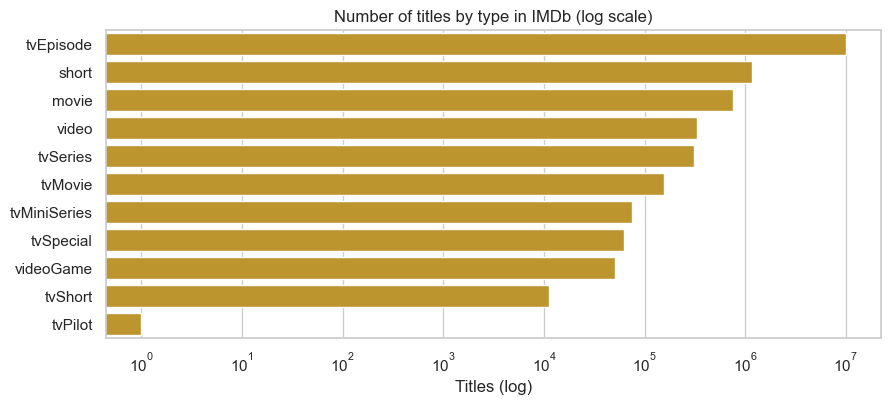

titleType
tvEpisode       77.4
short            9.0
movie            5.9
video            2.6
tvSeries         2.4
tvMovie          1.2
tvMiniSeries     0.6
tvSpecial        0.5
videoGame        0.4
tvShort          0.1
tvPilot          0.0
Name: titles, dtype: float64

In [9]:
tc = type_summary['titles'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=tc.values, y=tc.index, ax=ax, color=GOLD)
ax.set(xscale='log', title='Number of titles by type in IMDb (log scale)', xlabel='Titles (log)', ylabel='')
plt.show()
(tc / tc.sum() * 100).round(1)

In [10]:
rated_share = type_summary['rated_titles'] / type_summary['titles'] * 100
rated_share.sort_values(ascending=False).round(1).rename('% of titles with a rating')

titleType
movie           46.2
videoGame       40.0
tvSeries        37.5
tvMovie         36.6
tvMiniSeries    35.9
tvShort         24.0
tvSpecial       23.2
video           18.2
short           15.9
tvEpisode        8.9
tvPilot          0.0
Name: % of titles with a rating, dtype: float64

### 4.2 Genres

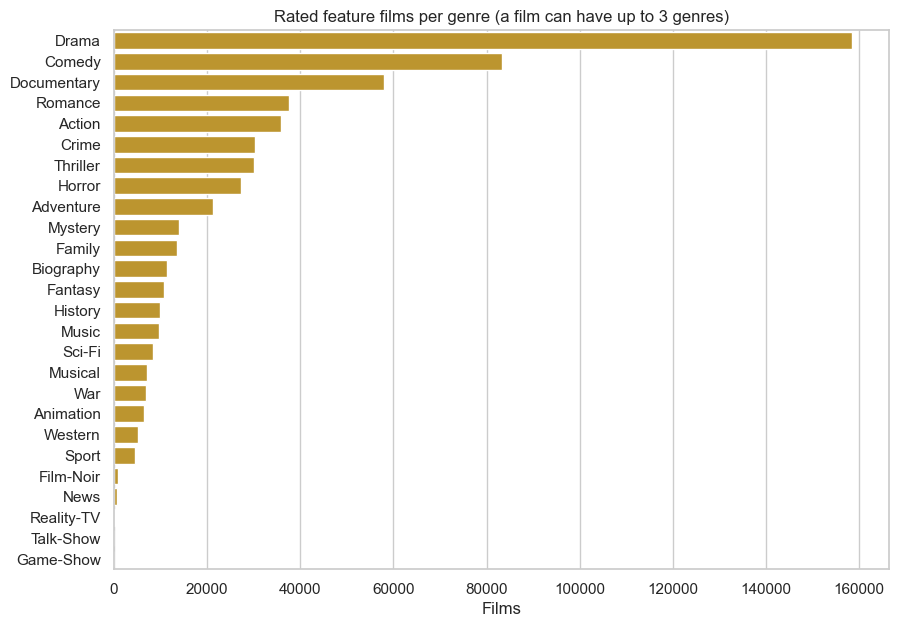

genre
Drama          158502
Comedy          83229
Documentary     58036
Romance         37665
Action          35870
Crime           30358
Thriller        30131
Horror          27256
Adventure       21157
Mystery         13920
Name: count, dtype: int64

In [11]:
genre_long = movies[['tconst', 'genres', 'averageRating', 'numVotes', 'runtimeMinutes', 'decade']].assign(
    genre=movies['genres'].str.split(',')).explode('genre')
genre_long = genre_long[genre_long['genre'] != 'Unknown']
genre_counts = genre_long['genre'].value_counts()
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=genre_counts.values, y=genre_counts.index, ax=ax, color=GOLD)
ax.set(title='Rated feature films per genre (a film can have up to 3 genres)', xlabel='Films', ylabel='')
plt.show()
genre_counts.head(10)

### 4.3 Release year

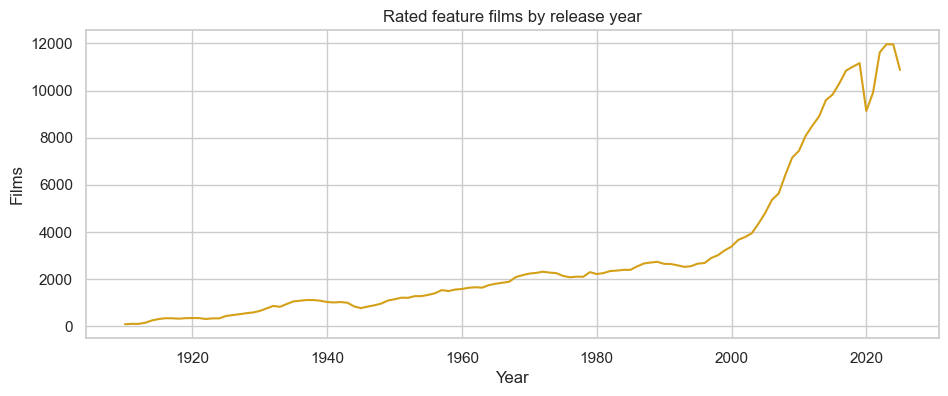

Films released 2000 or later: 62.4%


(np.int64(2023), 11968)

In [12]:
per_year = movies.groupby('startYear').size()
fig, ax = plt.subplots(figsize=(11, 4))
per_year.loc[1910:2025].plot(ax=ax, color=GOLD)
ax.set(title='Rated feature films by release year', xlabel='Year', ylabel='Films')
plt.show()
print('Films released 2000 or later:', f"{(movies['startYear'] >= 2000).mean():.1%}")
per_year.idxmax(), per_year.max()

### 4.4 Runtime

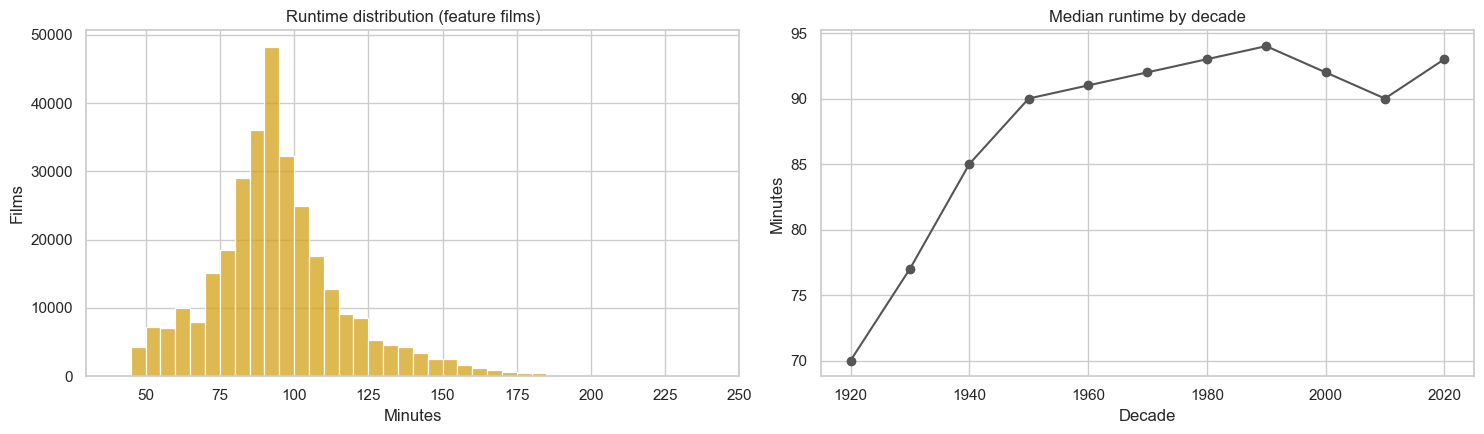

decade
1920    70.0
1930    77.0
1940    85.0
1950    90.0
1960    91.0
1970    92.0
1980    93.0
1990    94.0
2000    92.0
2010    90.0
2020    93.0
Name: runtimeMinutes, dtype: float64

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(movies['runtimeMinutes'].dropna(), bins=np.arange(40, 241, 5), ax=axes[0], color=GOLD)
axes[0].set(title='Runtime distribution (feature films)', xlabel='Minutes', ylabel='Films')
rt_dec = movies[movies['decade'] >= 1920].groupby('decade')['runtimeMinutes'].median()
rt_dec.plot(ax=axes[1], marker='o', color='#555')
axes[1].set(title='Median runtime by decade', xlabel='Decade', ylabel='Minutes')
plt.tight_layout(); plt.show()
rt_dec

## 5. Ratings and votes

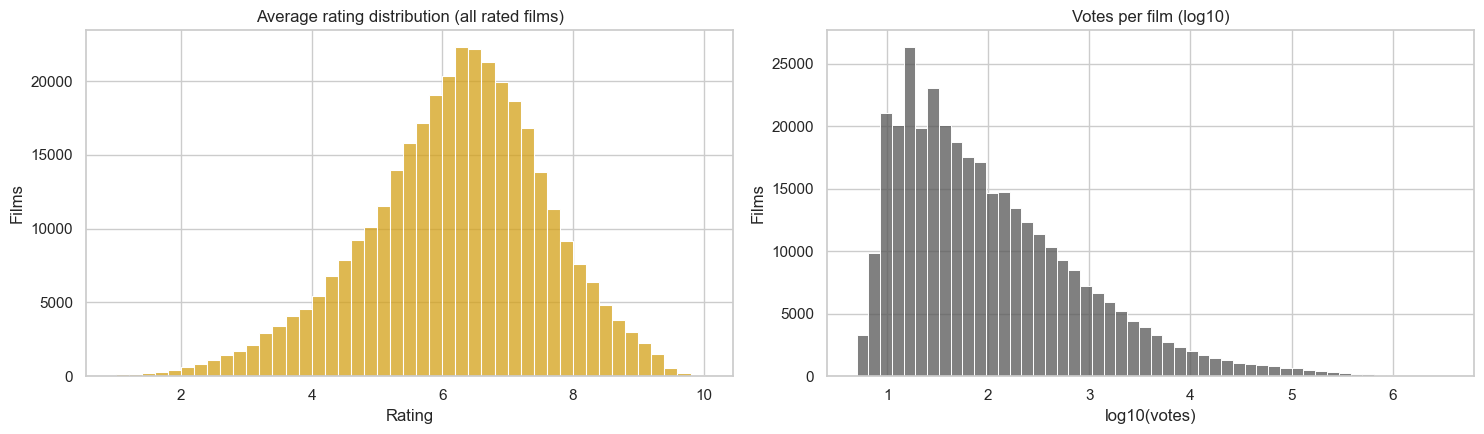

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(movies['averageRating'], bins=np.arange(1, 10.1, 0.2), ax=axes[0], color=GOLD)
axes[0].set(title='Average rating distribution (all rated films)', xlabel='Rating', ylabel='Films')
sns.histplot(np.log10(movies['numVotes']), bins=50, ax=axes[1], color='#555')
axes[1].set(title='Votes per film (log10)', xlabel='log10(votes)', ylabel='Films')
plt.tight_layout(); plt.show()

In [15]:
bins = [0, 10, 100, 1_000, 10_000, 100_000, np.inf]
labels = ['5-10', '11-100', '101-1k', '1k-10k', '10k-100k', '100k+']
movies['votes_band'] = pd.cut(movies['numVotes'], bins=[4, 10, 100, 1000, 10000, 100000, np.inf], labels=labels)
vb = movies.groupby('votes_band', observed=True)['averageRating'].agg(['count', 'mean', 'std']).round(2)
vb

,count,mean,std
votes_band,,,
5-10,26891,6.62,1.50
11-100,173117,6.29,1.41
101-1k,97652,5.74,1.30
1k-10k,36798,6.11,1.19
10k-100k,9932,6.47,1.03
100k+,2770,6.99,0.82


Films with very few votes have a higher and much more spread-out average rating (small samples, often friends and cast). As votes grow, the spread narrows.

### 5.1 Highly rated and most popular titles
A raw top-10 by rating would be filled with films that have a handful of votes. We rank with a **weighted rating** (the IMDb Top-250 style Bayesian formula):

$WR = \frac{v}{v+m}R + \frac{m}{v+m}C$

where *R* = film's average, *v* = its votes, *m* = 25,000 (minimum votes) and *C* = mean rating of popular films.

In [16]:
C = popular['averageRating'].mean()
m = 25_000
top = movies[movies['numVotes'] >= m].copy()
top['weighted_rating'] = (top['numVotes'] / (top['numVotes'] + m)) * top['averageRating'] + (m / (top['numVotes'] + m)) * C
top.nlargest(15, 'weighted_rating')[['primaryTitle', 'startYear', 'genres', 'averageRating', 'numVotes', 'weighted_rating']].round(2)

,primaryTitle,startYear,genres,averageRating,numVotes,weighted_rating
62437,The Shawshank Redemption,1994,Drama,9.3,3265691,9.28
37492,The Godfather,1972,"Crime,Drama",9.2,2272971,9.17
140587,The Dark Knight,2008,"Crime,Thriller",9.1,3251483,9.08
80027,The Lord of the Rings: The Return of the King,2003,"Adventure,Drama,Fantasy",9.0,2208508,8.97
60866,Schindler's List,1993,"Biography,Drama,History",9.0,1613953,8.96
39424,The Godfather Part II,1974,"Crime,Drama",9.0,1524357,8.96
24315,12 Angry Men,1957,"Crime,Drama",9.0,1012429,8.93
67102,The Lord of the Rings: The Fellowship of the Ring,2001,"Adventure,Drama,Fantasy",8.9,2253033,8.87
184212,Inception,2010,"Adventure,Sci-Fi,Thriller",8.8,2890478,8.78
72472,Fight Club,1999,"Crime,Drama,Thriller",8.8,2684528,8.78


In [17]:
movies.nlargest(10, 'numVotes')[['primaryTitle', 'startYear', 'genres', 'averageRating', 'numVotes']]

,primaryTitle,startYear,genres,averageRating,numVotes
62437,The Shawshank Redemption,1994,Drama,9.3,3265691
140587,The Dark Knight,2008,"Crime,Thriller",9.1,3251483
184212,Inception,2010,"Adventure,Sci-Fi,Thriller",8.8,2890478
72472,Fight Club,1999,"Crime,Drama,Thriller",8.8,2684528
146540,Interstellar,2014,"Adventure,Sci-Fi",8.7,2635464
61707,Forrest Gump,1994,"Drama,Romance",8.8,2553923
62291,Pulp Fiction,1994,"Crime,Drama",8.8,2484082
71161,The Matrix,1999,"Action,Sci-Fi",8.7,2294682
37492,The Godfather,1972,"Crime,Drama",9.2,2272971
67102,The Lord of the Rings: The Fellowship of the Ring,2001,"Adventure,Drama,Fantasy",8.9,2253033


### 5.2 Genre ratings and popularity

In [18]:
gpop = genre_long[genre_long['numVotes'] >= 1000]
genre_stats = gpop.groupby('genre').agg(films=('tconst', 'size'), mean_rating=('averageRating', 'mean'),
                                        median_votes=('numVotes', 'median'), total_votes=('numVotes', 'sum'),
                                        median_runtime=('runtimeMinutes', 'median'))
genre_stats = genre_stats[genre_stats['films'] >= 200].sort_values('mean_rating', ascending=False)
genre_stats.round(2)

,films,mean_rating,median_votes,total_votes,median_runtime
genre,,,,,
Documentary,2605,7.19,2321.0,14063868,93.0
Biography,2633,6.90,4607.0,82490333,110.0
Film-Noir,464,6.85,2976.5,4062614,88.0
History,1948,6.82,3557.0,35822304,114.0
War,1235,6.77,3355.0,28923057,107.0
Music,1503,6.71,3402.0,25923397,103.0
Animation,1646,6.63,4917.0,78642474,90.0
Musical,861,6.58,2894.0,11795966,111.0
Sport,927,6.53,3748.0,21418480,103.0


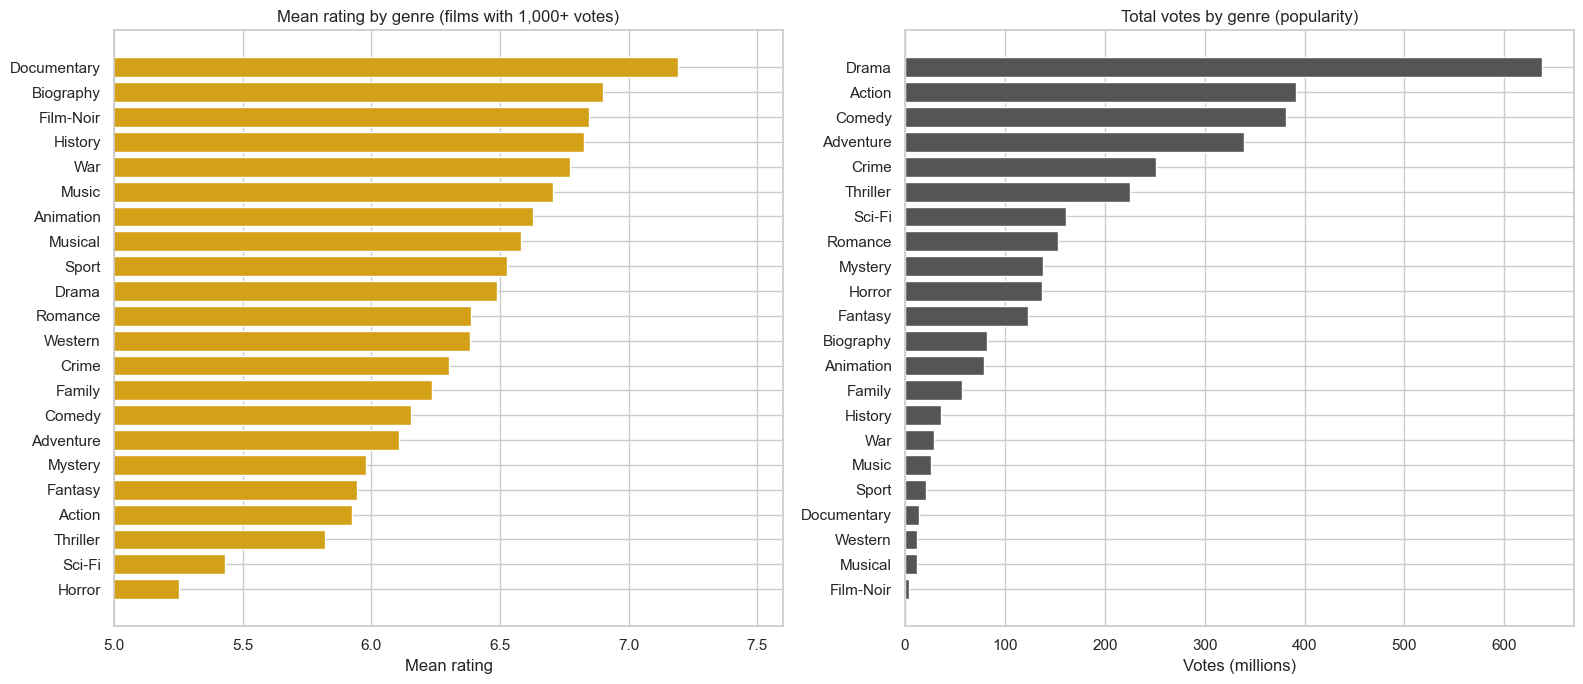

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
gs = genre_stats.sort_values('mean_rating')
axes[0].barh(gs.index, gs['mean_rating'], color=GOLD)
axes[0].set(title='Mean rating by genre (films with 1,000+ votes)', xlabel='Mean rating', xlim=(5, 7.6))
gv = genre_stats.sort_values('total_votes')
axes[1].barh(gv.index, gv['total_votes'] / 1e6, color='#555')
axes[1].set(title='Total votes by genre (popularity)', xlabel='Votes (millions)')
plt.tight_layout(); plt.show()

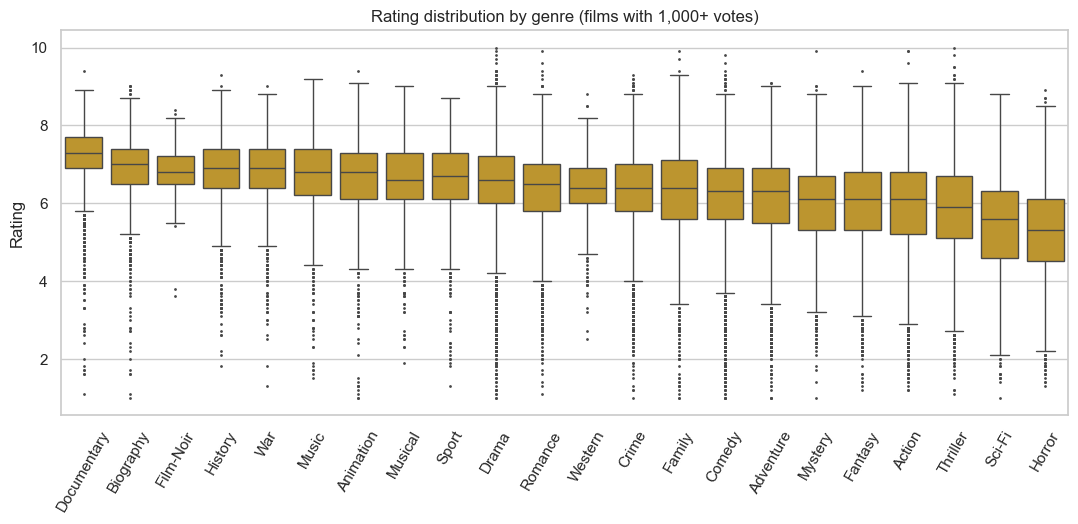

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))
order = genre_stats.sort_values('mean_rating', ascending=False).index
sns.boxplot(data=gpop[gpop['genre'].isin(order)], x='genre', y='averageRating', order=order, ax=ax, color=GOLD, fliersize=1)
ax.set(title='Rating distribution by genre (films with 1,000+ votes)', xlabel='', ylabel='Rating')
plt.xticks(rotation=60); plt.show()

## 6. Relationships between rating, runtime, year and votes

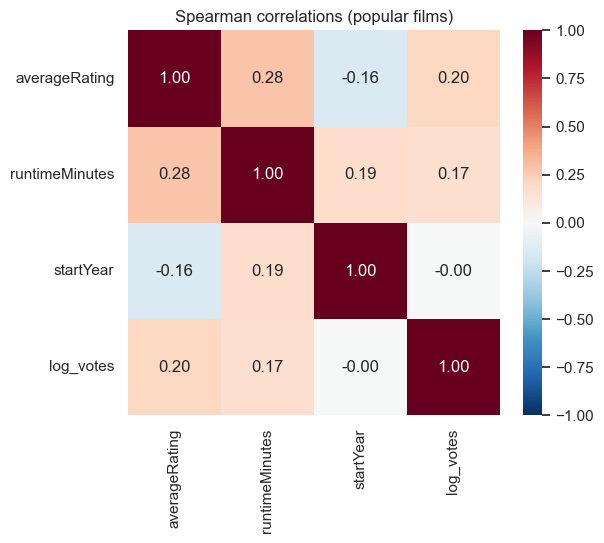

In [21]:
rel = popular[['averageRating', 'numVotes', 'runtimeMinutes', 'startYear']].astype(float)
rel['log_votes'] = np.log10(rel['numVotes'])
corr = rel.drop(columns='numVotes').corr(method='spearman')
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlations (popular films)')
plt.show()

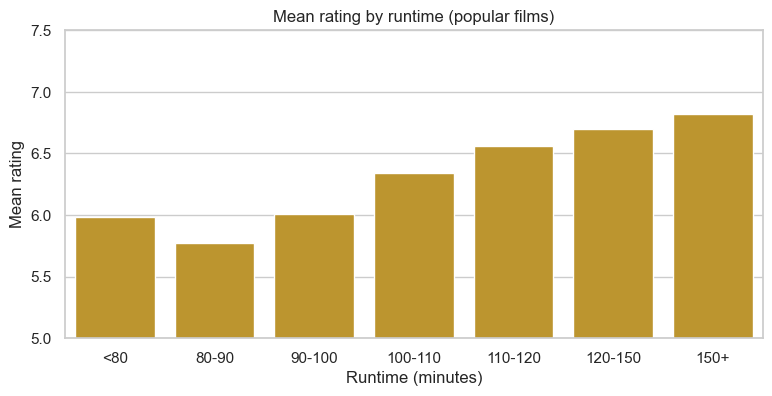

,count,mean
runtime_band,,
<80,3118,5.98
80-90,8877,5.77
90-100,12820,6.01
100-110,9336,6.34
110-120,5717,6.56
120-150,7351,6.70
150+,2247,6.82


In [22]:
popular['runtime_band'] = pd.cut(popular['runtimeMinutes'], [40, 80, 90, 100, 110, 120, 150, 600],
                                 labels=['<80', '80-90', '90-100', '100-110', '110-120', '120-150', '150+'])
rb = popular.groupby('runtime_band', observed=True)['averageRating'].agg(['count', 'mean']).round(2)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=rb.index.astype(str), y=rb['mean'], ax=ax, color=GOLD)
ax.set(title='Mean rating by runtime (popular films)', xlabel='Runtime (minutes)', ylabel='Mean rating', ylim=(5, 7.5))
plt.show()
rb

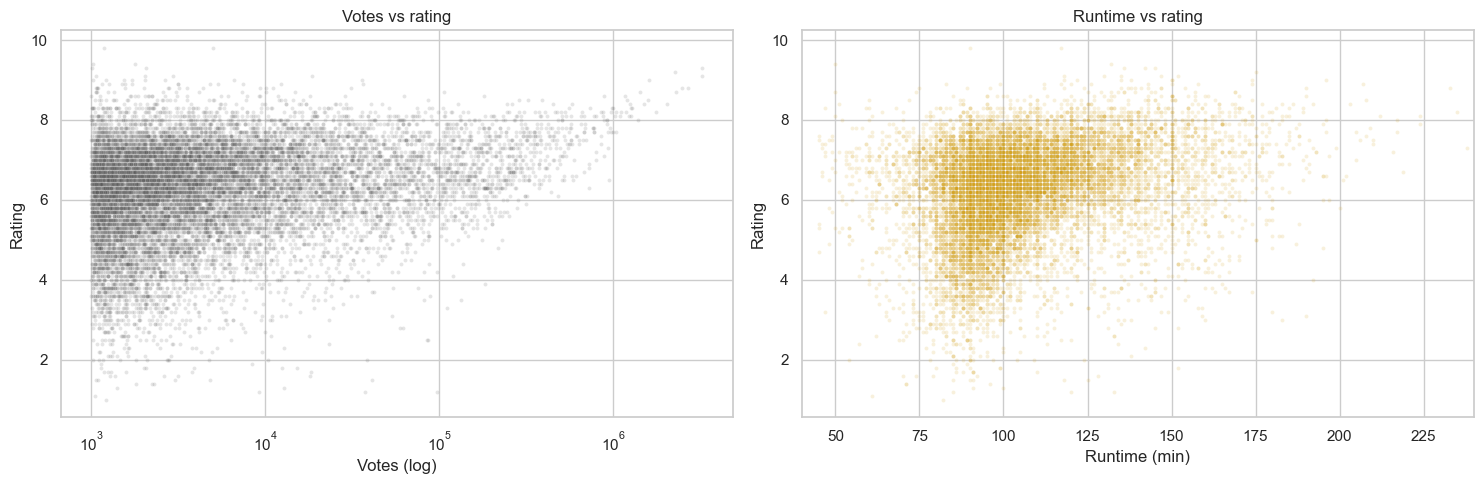

In [23]:
sample = popular.sample(min(15000, len(popular)), random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=sample, x='numVotes', y='averageRating', alpha=0.15, s=8, ax=axes[0], color='#555')
axes[0].set(xscale='log', title='Votes vs rating', xlabel='Votes (log)', ylabel='Rating')
sns.scatterplot(data=sample, x='runtimeMinutes', y='averageRating', alpha=0.15, s=8, ax=axes[1], color=GOLD)
axes[1].set(xlim=(40, 240), title='Runtime vs rating', xlabel='Runtime (min)', ylabel='Rating')
plt.tight_layout(); plt.show()

## 7. Comparing genres and time periods

In [24]:
dec = popular[popular['decade'].between(1930, 2020)].groupby('decade').agg(
    films=('tconst', 'size'), mean_rating=('averageRating', 'mean'), median_votes=('numVotes', 'median'),
    median_runtime=('runtimeMinutes', 'median')).round(2)
dec

,films,mean_rating,median_votes,median_runtime
decade,,,,
1930,822,6.79,2173.0,85.0
1940,1148,6.80,2629.5,94.0
1950,1631,6.65,2505.0,94.0
1960,2045,6.60,2838.0,100.0
1970,2623,6.47,2771.0,98.0
1980,3383,6.27,3723.0,98.0
1990,4351,6.33,5040.0,101.0
2000,8491,6.20,4085.0,100.0
2010,14563,6.07,3326.0,100.0


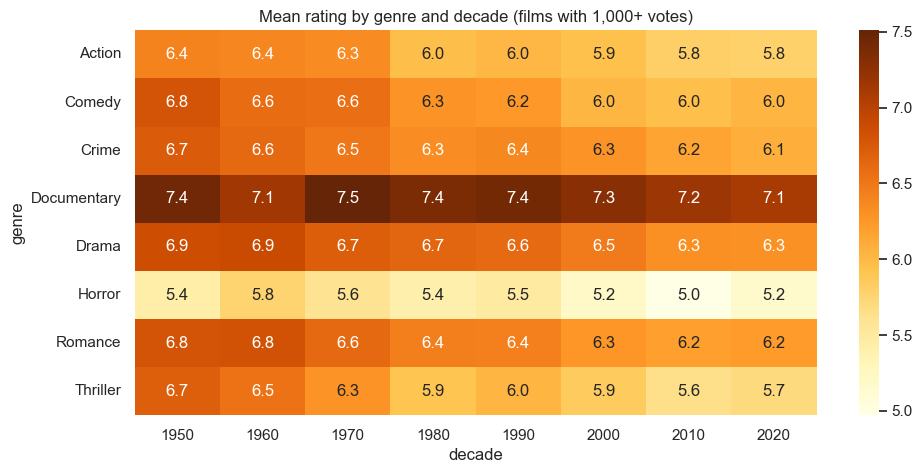

In [25]:
main_genres = ['Drama', 'Comedy', 'Action', 'Horror', 'Thriller', 'Romance', 'Documentary', 'Crime']
gd = (genre_long[(genre_long['numVotes'] >= 1000) & genre_long['genre'].isin(main_genres) & genre_long['decade'].between(1950, 2020)]
      .pivot_table(index='genre', columns='decade', values='averageRating', aggfunc='mean'))
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(gd, annot=True, fmt='.1f', cmap='YlOrBr', ax=ax)
ax.set_title('Mean rating by genre and decade (films with 1,000+ votes)')
plt.show()

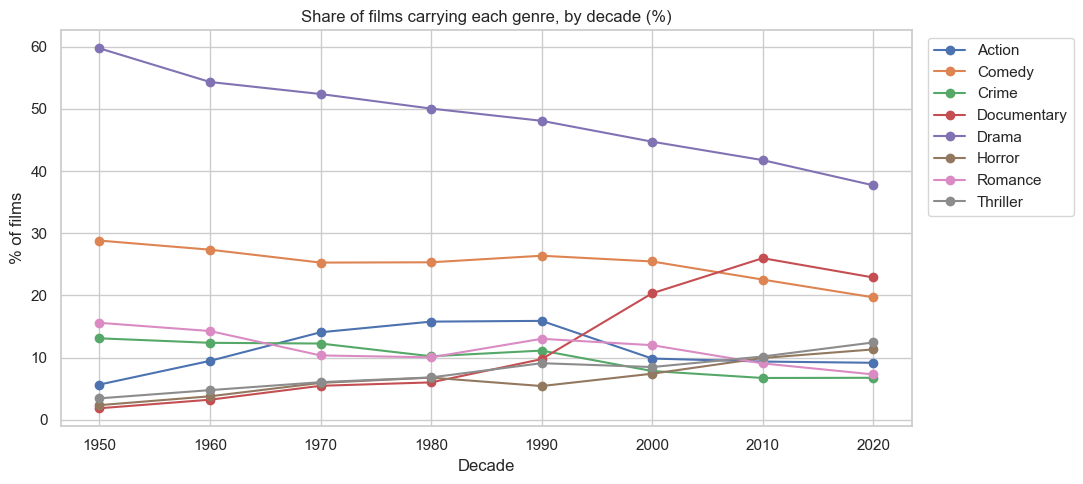

genre,Action,Comedy,Crime,Documentary,Drama,Horror,Romance,Thriller
decade,,,,,,,,
1950,5.7,28.8,13.1,1.9,59.7,2.4,15.6,3.5
1960,9.5,27.4,12.4,3.2,54.3,3.8,14.3,4.8
1970,14.1,25.3,12.3,5.5,52.4,5.9,10.4,6.1
1980,15.8,25.3,10.2,6.0,50.0,6.8,10.0,6.8
1990,15.9,26.4,11.1,9.8,48.1,5.4,13.0,9.1
2000,9.9,25.5,7.8,20.4,44.7,7.4,12.0,8.5
2010,9.4,22.6,6.7,26.0,41.8,9.9,9.1,10.2
2020,9.2,19.7,6.8,22.9,37.7,11.3,7.3,12.4


In [26]:
share = (genre_long[genre_long['decade'].between(1950, 2020) & genre_long['genre'].isin(main_genres)]
         .groupby(['decade', 'genre']).size().unstack(fill_value=0))
share = share.div(movies[movies['decade'].between(1950, 2020)].groupby('decade').size(), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 5))
share.plot(ax=ax, marker='o')
ax.set(title='Share of films carrying each genre, by decade (%)', xlabel='Decade', ylabel='% of films')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
share.round(1)

## 8. Key insights and conclusions

### Cleaning summary
- IMDb's `\N` markers were read as missing values. There are no duplicate IDs and no duplicate rows.
- Missing values among rated movies:
  - runtime: 8.4%
  - genre: 3.3%, labelled "Unknown"
  - year: 33 films, dropped
- 153 implausible runtimes (under 40 or over 600 minutes) were treated as errors and set to missing.
- Adult titles were excluded.
- Because vote counts are extremely skewed, rating comparisons use **popular films with 1,000 or more votes** (49,528 films, 14% of rated films, holding 97% of all movie votes). The top list uses a weighted (Bayesian) rating.

### Key findings
1. **Title types:**
   - IMDb is mostly TV episodes (77% of all titles), followed by shorts (9%) and feature films (5.9%).
   - Only 13% of titles have a rating. Feature films are the most often rated type (46%), and TV episodes the least (9%).
2. **Genres:**
   - Drama is by far the most common movie genre (158,502 rated films), followed by Comedy (83,229) and Documentary (58,036).
   - Over time, Documentary grew from about 2% of films in the 1950s to about 26% in the 2010s.
   - Horror and Thriller also grew, while Drama, Romance and Crime shrank as a share.
3. **Release years:**
   - 62% of rated films were released in 2000 or later.
   - The peak year is 2023, with 11,968 rated films.
4. **Runtime:**
   - The median feature film runs 91 minutes.
   - Median runtime grew from 70 minutes in the 1920s to about 90–94 minutes from the 1950s onwards, and has stayed stable since.
5. **Ratings and votes:**
   - The average rating is 6.15 (median 6.3), and the distribution is slightly skewed towards high ratings.
   - Votes are extremely uneven: the median film has only 66 votes, but the top 1% have more than 75,000.
   - Films with very few votes (5–10) average 6.62 and vary widely (std 1.50), which shows that small samples are unreliable.
   - Among films with 1,000+ votes, the most-voted films are rated higher: 100k+ votes average 6.99, against 6.11 for 1k–10k votes.
6. **Highly rated titles:** the weighted top list is led by *The Shawshank Redemption* (9.3 from 3.27M votes), *The Godfather* (9.2), *The Dark Knight* (9.1) and *The Return of the King* (9.0). The most-voted films overlap strongly with the top-rated list.
7. **Genres: quality vs popularity** (films with 1,000+ votes):
   - **Highest rated:** Documentary (7.19), Biography (6.90), Film-Noir (6.85), History (6.82) and War (6.77).
   - **Lowest rated:** Horror (5.25), Sci-Fi (5.43), Thriller (5.82) and Action (5.93).
   - **Most total votes:** Drama, Action, Comedy and Adventure.
   - Popularity and rating differ: Action and Sci-Fi draw huge audiences but have lower average ratings.
8. **Relationships** (Spearman correlation, popular films):
   - Rating vs runtime: +0.28. Longer films are rated higher, rising from 5.77 for 80–90 minutes to 6.82 for 150+ minutes.
   - Rating vs votes: +0.20.
   - Rating vs year: −0.16. Mean rating fell from about 6.8 for 1930s–40s films to about 6.1 for the 2010s–2020s.
   - All of these correlations are weak to moderate.
9. **The age effect is likely survivorship:** older films that still collect 1,000+ votes today tend to be the well-remembered classics. Newer films include many more average releases.

### Insights about audience preferences
- Audiences give the highest ratings to factual and serious genres (documentary, biography, history, war). Entertainment genres (action, comedy, adventure) attract the most votes, so the most-watched content is not necessarily the best-rated.
- Horror is the lowest-rated genre even though its share of production keeps growing. Producers keep making it because of audience demand, not critical approval.
- Longer, more ambitious films are associated with higher ratings, but this does not show that adding minutes improves a film.
- A rating based on few votes should not be trusted. Ranking needs a vote threshold or a weighted rating.

### Limitations
- The data is a current snapshot, so recent films have had less time to collect votes.
- One film can carry up to three genres.
- Ratings come from self-selected IMDb users.
- All relationships are correlations, not causes.
